In [1]:
# ------------------------------
# Importing necessary libraries
# ------------------------------

# Primary libraries
import pandas as pd
import os
import glob
import requests
from tqdm import tqdm

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

print("Successfully loaded all libraries!")

Successfully loaded all libraries!


In [ ]:
# ---------------------------------------------------
# Downloading football data from football-data.co.uk
# ---------------------------------------------------

leagues = {
    'E0': 'premier_league',
    'SP1': 'la_liga', 
    'D1': 'bundesliga',
    'I1': 'serie_a',
    'F1': 'ligue_1'
}

seasons = [
    '1415', '1516', '1617', '1718', '1819',
    '1920', '2021', '2122', '2223', '2324', '2425'
]

base_url = "https://www.football-data.co.uk/mmz4281"
save_dir = "../data/raw/football"

os.makedirs(save_dir, exist_ok=True)

errors = []

for season in seasons:
    for code, name in tqdm(leagues.items(), desc=f"Season {season}"):
        url = f"{base_url}/{season}/{code}.csv"
        filename = f"{save_dir}/{name}_{season}.csv"
        
        if os.path.exists(filename):
            continue
            
        response = requests.get(url)
        
        if response.status_code == 200:
            with open(filename, 'wb') as f:
                f.write(response.content)
        else:
            errors.append(f"ERROR: {name} {season} - status {response.status_code}")

print("\nDownload completed!")
print(f"Successfully downloaded files: {len(os.listdir(save_dir))}")

if errors:
    print("\nErrors:")
    for e in errors:
        print(e)
else:
    print("No errors!")

Season 2425: 100%|██████████| 5/5 [00:00<00:00, 4989.66it/s]


Download completed!
Successfully downloaded files: 55
No errors!


In [71]:
# ------------------------
# Basic data exploration
# ------------------------

df = pd.read_csv("../data/raw/football/premier_league_2425.csv")

print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")
print(f"\nColumns:\n{df.columns.tolist()}")

Number of rows: 380
Number of columns: 120

Columns:
['Div', 'Date', 'Time', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG', 'FTR', 'HTHG', 'HTAG', 'HTR', 'Referee', 'HS', 'AS', 'HST', 'AST', 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR', 'B365H', 'B365D', 'B365A', 'BWH', 'BWD', 'BWA', 'BFH', 'BFD', 'BFA', 'PSH', 'PSD', 'PSA', 'WHH', 'WHD', 'WHA', '1XBH', '1XBD', '1XBA', 'MaxH', 'MaxD', 'MaxA', 'AvgH', 'AvgD', 'AvgA', 'BFEH', 'BFED', 'BFEA', 'B365>2.5', 'B365<2.5', 'P>2.5', 'P<2.5', 'Max>2.5', 'Max<2.5', 'Avg>2.5', 'Avg<2.5', 'BFE>2.5', 'BFE<2.5', 'AHh', 'B365AHH', 'B365AHA', 'PAHH', 'PAHA', 'MaxAHH', 'MaxAHA', 'AvgAHH', 'AvgAHA', 'BFEAHH', 'BFEAHA', 'B365CH', 'B365CD', 'B365CA', 'BWCH', 'BWCD', 'BWCA', 'BFCH', 'BFCD', 'BFCA', 'PSCH', 'PSCD', 'PSCA', 'WHCH', 'WHCD', 'WHCA', '1XBCH', '1XBCD', '1XBCA', 'MaxCH', 'MaxCD', 'MaxCA', 'AvgCH', 'AvgCD', 'AvgCA', 'BFECH', 'BFECD', 'BFECA', 'B365C>2.5', 'B365C<2.5', 'PC>2.5', 'PC<2.5', 'MaxC>2.5', 'MaxC<2.5', 'AvgC>2.5', 'AvgC<2.5', 'BFEC>2.5', 'BFEC<2.

In [ ]:
# ----------------------------------------
# Loading and combining all football data
# ----------------------------------------

all_files = glob.glob("../data/raw/football/*.csv")

dfs = []

for file in all_files:
    df_temp = pd.read_csv(file, encoding='utf-8', low_memory=False)
    
    basename = os.path.basename(file).replace('.csv', '')
    parts = basename.rsplit('_', 1)
    
    df_temp = pd.concat([
        df_temp,
        pd.DataFrame({
            'league': parts[0],
            'season': parts[1]
        }, index=df_temp.index)
    ], axis=1)
    
    dfs.append(df_temp)

df_all = pd.concat(dfs, ignore_index=True)

print(f"Total rows: {df_all.shape[0]}")
print(f"Total columns: {df_all.shape[1]}")
print(f"\nRows per league:")
print(df_all['league'].value_counts())
print(f"\nRows per season:")
print(df_all['season'].value_counts().sort_index())

Total rows: 19841
Total columns: 158

Rows per league:
league
serie_a           4182
premier_league    4181
la_liga           4180
ligue_1           3932
bundesliga        3366
Name: count, dtype: int64

Rows per season:
season
1415    1828
1516    1828
1617    1826
1718    1826
1819    1826
1920    1725
2021    1826
2122    1826
2223    1826
2324    1752
2425    1752
Name: count, dtype: int64


In [ ]:
# -------------------------
# Keeping relevant columns
# -------------------------

cols_to_keep = [
    # Match info
    'Div', 'Date', 'HomeTeam', 'AwayTeam', 'league', 'season',
    
    # Full time result (TARGET)
    'FTR', 'FTHG', 'FTAG',
    
    # Half time
    'HTHG', 'HTAG', 'HTR',
    
    # Match stats
    'HS', 'AS',       # Shots
    'HST', 'AST',     # Shots on target
    'HC', 'AC',       # Corners
    'HF', 'AF',       # Fouls
    'HY', 'AY',       # Yellow cards
    'HR', 'AR',       # Red cards
    
    # Market average and maximum odds
    'AvgH', 'AvgD', 'AvgA',
    'MaxH', 'MaxD', 'MaxA',
]

cols_to_keep = [col for col in cols_to_keep if col in df_all.columns]

df_all = df_all[cols_to_keep]

print(f"Remaining columns: {df_all.shape[1]}")
print(f"Total rows: {df_all.shape[0]}")
print(f"\nMissing values:")
print(df_all.isnull().sum()[df_all.isnull().sum() > 0])

Remaining columns: 30
Total rows: 19841

Missing values:
Div            4
Date           4
HomeTeam       4
AwayTeam       4
FTR            4
FTHG           4
FTAG           4
HTHG           7
HTAG           7
HTR            7
HS             6
AS             6
HST            6
AST            6
HC             6
AC             6
HF             6
AF             6
HY             7
AY             6
HR             6
AR             6
AvgH        9135
AvgD        9135
AvgA        9135
MaxH        9135
MaxD        9135
MaxA        9135
dtype: int64


In [ ]:
# ----------------------------------------------------
# Checking which seasons or leagues have missing odds
# ----------------------------------------------------

print("Missing odds by season:")
print(df_all[df_all['AvgH'].isnull()]['season'].value_counts().sort_index())

print("\nMissing odds by league:")
print(df_all[df_all['AvgH'].isnull()]['league'].value_counts())

Missing odds by season:
season
1415    1828
1516    1828
1617    1826
1718    1826
1819    1826
2122       1
Name: count, dtype: int64

Missing odds by league:
league
serie_a           1903
ligue_1           1901
premier_league    1901
la_liga           1900
bundesliga        1530
Name: count, dtype: int64


In [ ]:
# --------------------------------------------
# Droping rows with missing essential columns 
# --------------------------------------------

print(f"Rows before cleaning: {df_all.shape[0]}")
print(f"\nRows with any missing value: {df_all.isnull().any(axis=1).sum()}")

essential_cols = [
    'Date', 'HomeTeam', 'AwayTeam', 'FTR', 
    'FTHG', 'FTAG', 'HTR', 'HTHG', 'HTAG',
    'HS', 'AS', 'HST', 'AST',
    'HC', 'AC', 'HF', 'AF', 'HY', 'AY', 'HR', 'AR'
]

df_all = df_all.dropna(subset=essential_cols)

print(f"\nRows after cleaning: {df_all.shape[0]}")
print(f"Rows dropped: {19841 - df_all.shape[0]}")

Rows before cleaning: 19841

Rows with any missing value: 9136

Rows after cleaning: 19833
Rows dropped: 8


In [ ]:
# --------------------------------------------------------
# Converting Date to datetime and sorting chronologically
# --------------------------------------------------------

df_all['Date'] = pd.to_datetime(df_all['Date'], dayfirst=True, format='mixed')
df_all = df_all.sort_values('Date').reset_index(drop=True)

print(f"Date range: {df_all['Date'].min()} - {df_all['Date'].max()}")
print(f"\nData types:")
print(df_all.dtypes)

Date range: 2014-08-08 00:00:00 - 2025-05-25 00:00:00

Data types:
Div                    str
Date        datetime64[us]
HomeTeam               str
AwayTeam               str
league                 str
season                 str
FTR                    str
FTHG               float64
FTAG               float64
HTHG               float64
HTAG               float64
HTR                    str
HS                 float64
AS                 float64
HST                float64
AST                float64
HC                 float64
AC                 float64
HF                 float64
AF                 float64
HY                 float64
AY                 float64
HR                 float64
AR                 float64
AvgH               float64
AvgD               float64
AvgA               float64
MaxH               float64
MaxD               float64
MaxA               float64
dtype: object


In [ ]:
# --------------------------------------------------------------------------------------------------
# Converting integer columns from float64 to int64 and verifying target variable (FTR) distribution
# --------------------------------------------------------------------------------------------------

int_cols = [
    'FTHG', 'FTAG', 'HTHG', 'HTAG',
    'HS', 'AS', 'HST', 'AST',
    'HC', 'AC', 'HF', 'AF',
    'HY', 'AY', 'HR', 'AR'
]

df_all[int_cols] = df_all[int_cols].astype(int)

print("Updated data types:")
print(df_all[int_cols].dtypes)


print(f"\nUnique FTR values: {df_all['FTR'].unique()}")
print(f"\nFTR distribution:")
print(df_all['FTR'].value_counts())
print(f"\nFTR distribution (%):")
print((df_all['FTR'].value_counts(normalize=True) * 100).round(1))

Updated data types:
FTHG    int64
FTAG    int64
HTHG    int64
HTAG    int64
HS      int64
AS      int64
HST     int64
AST     int64
HC      int64
AC      int64
HF      int64
AF      int64
HY      int64
AY      int64
HR      int64
AR      int64
dtype: object

Unique FTR values: <StringArray>
['D', 'A', 'H']
Length: 3, dtype: str

FTR distribution:
FTR
H    8760
A    6087
D    4986
Name: count, dtype: int64

FTR distribution (%):
FTR
H    44.2
A    30.7
D    25.1
Name: proportion, dtype: float64


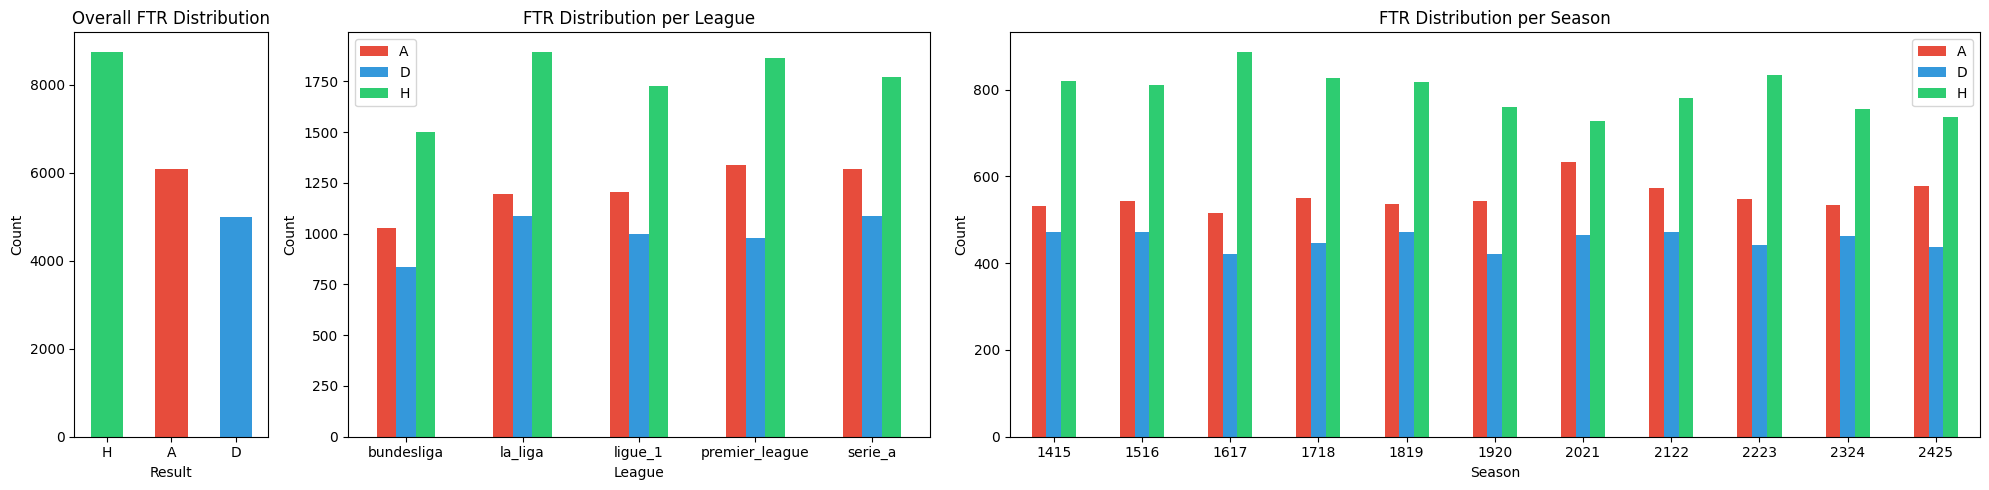

In [ ]:
# --------------------------------------------------------------------------------
# Visualising overall FTR distribution and FTR distribution per league and season
# --------------------------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(20, 5), gridspec_kw={'width_ratios': [1, 3, 5]})

# FTR overall distribution
ftr_counts = df_all['FTR'].value_counts()
ftr_counts.plot(kind='bar', ax=axes[0], color=['#2ecc71', '#e74c3c', '#3498db'], rot=0)
axes[0].set_title('Overall FTR Distribution')
axes[0].set_xlabel('Result')
axes[0].set_ylabel('Count')

# FTR distribution per league
ftr_league = df_all.groupby(['league', 'FTR']).size().unstack()
ftr_league.plot(kind='bar', ax=axes[1], color=['#e74c3c', '#3498db', '#2ecc71'], rot=0)
axes[1].set_title('FTR Distribution per League')
axes[1].set_xlabel('League')
axes[1].set_ylabel('Count')
axes[1].legend()

# FTR distribution per season
ftr_season = df_all.groupby(['season', 'FTR']).size().unstack()
ftr_season.plot(kind='bar', ax=axes[2], color=['#e74c3c', '#3498db', '#2ecc71'], rot=0)
axes[2].set_title('FTR Distribution per Season')
axes[2].set_xlabel('Season')
axes[2].set_ylabel('Count')
axes[2].legend()

plt.tight_layout()
plt.savefig('../results/figures/01_ftr_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

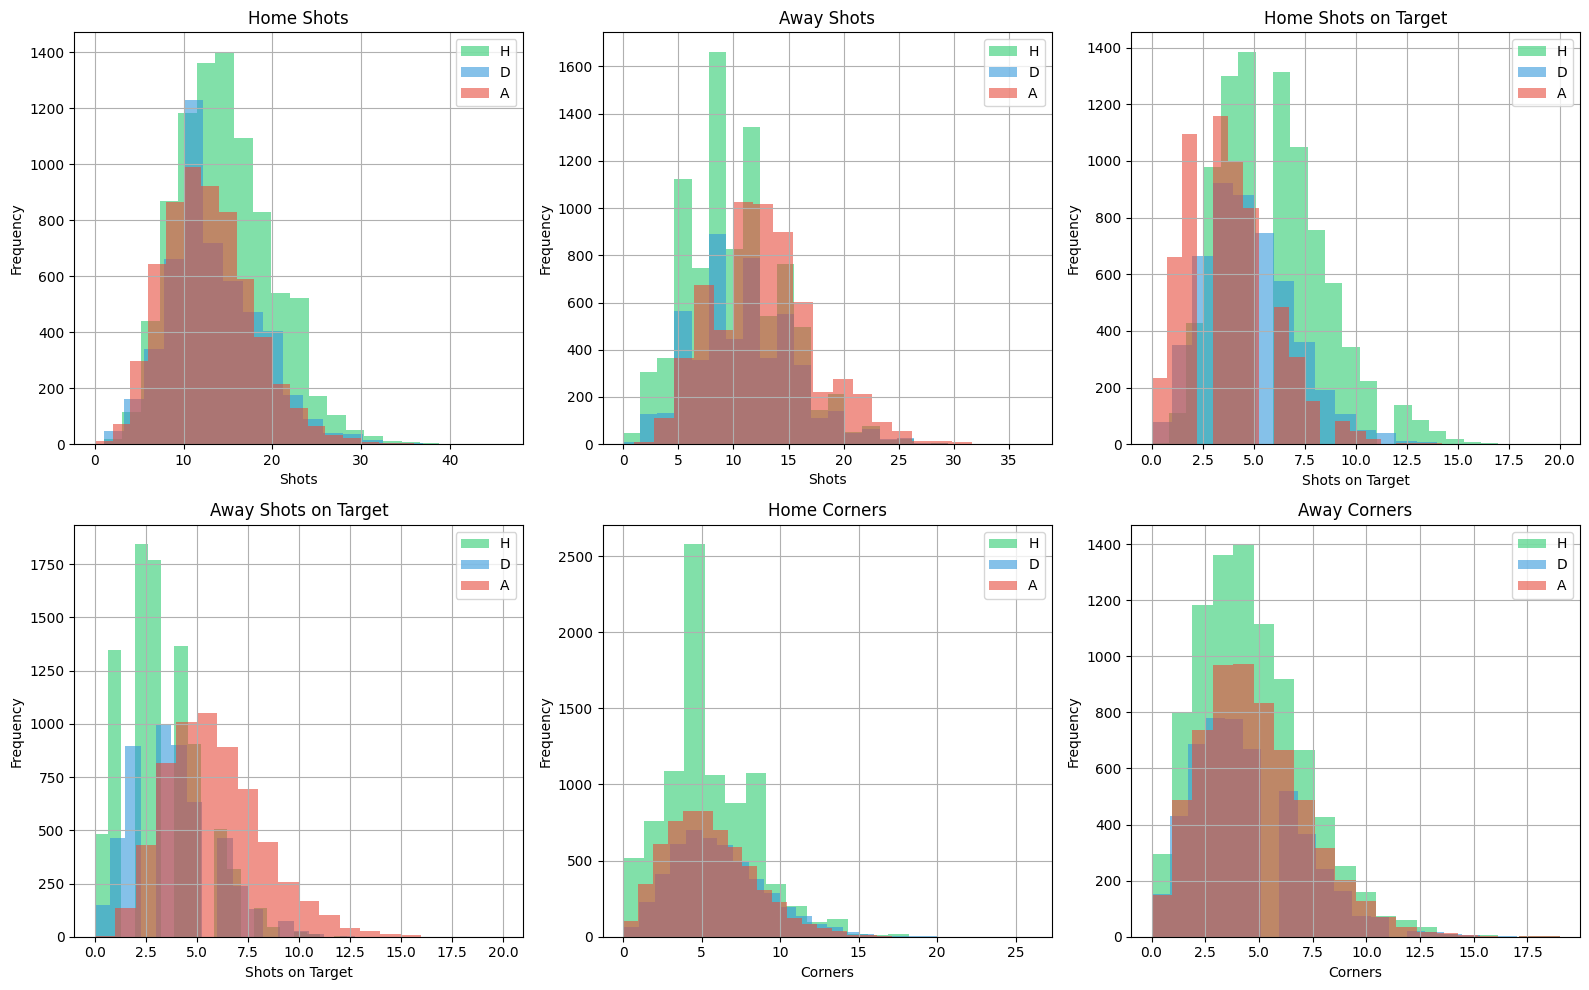

In [ ]:
# ----------------------------------------------------------
# Visualising match statistics distribution by result (FTR)
# ----------------------------------------------------------

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

stats = ['HS', 'AS', 'HST', 'AST', 'HC', 'AC']
titles = ['Home Shots', 'Away Shots', 'Home Shots on Target', 
          'Away Shots on Target', 'Home Corners', 'Away Corners']
x_labels = ['Shots', 'Shots', 'Shots on Target', 'Shots on Target', 'Corners', 'Corners']

for i, (stat, title) in enumerate(zip(stats, titles)):
    for result, color in zip(['H', 'D', 'A'], ['#2ecc71', '#3498db', '#e74c3c']):
        df_all[df_all['FTR'] == result][stat].hist(
            ax=axes[i], alpha=0.6, color=color, label=result, bins=20
        )
    axes[i].set_title(title)
    axes[i].set_xlabel(x_labels[i])
    axes[i].set_ylabel('Frequency')
    axes[i].legend()

plt.tight_layout()
plt.savefig('../results/figures/02_stats_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

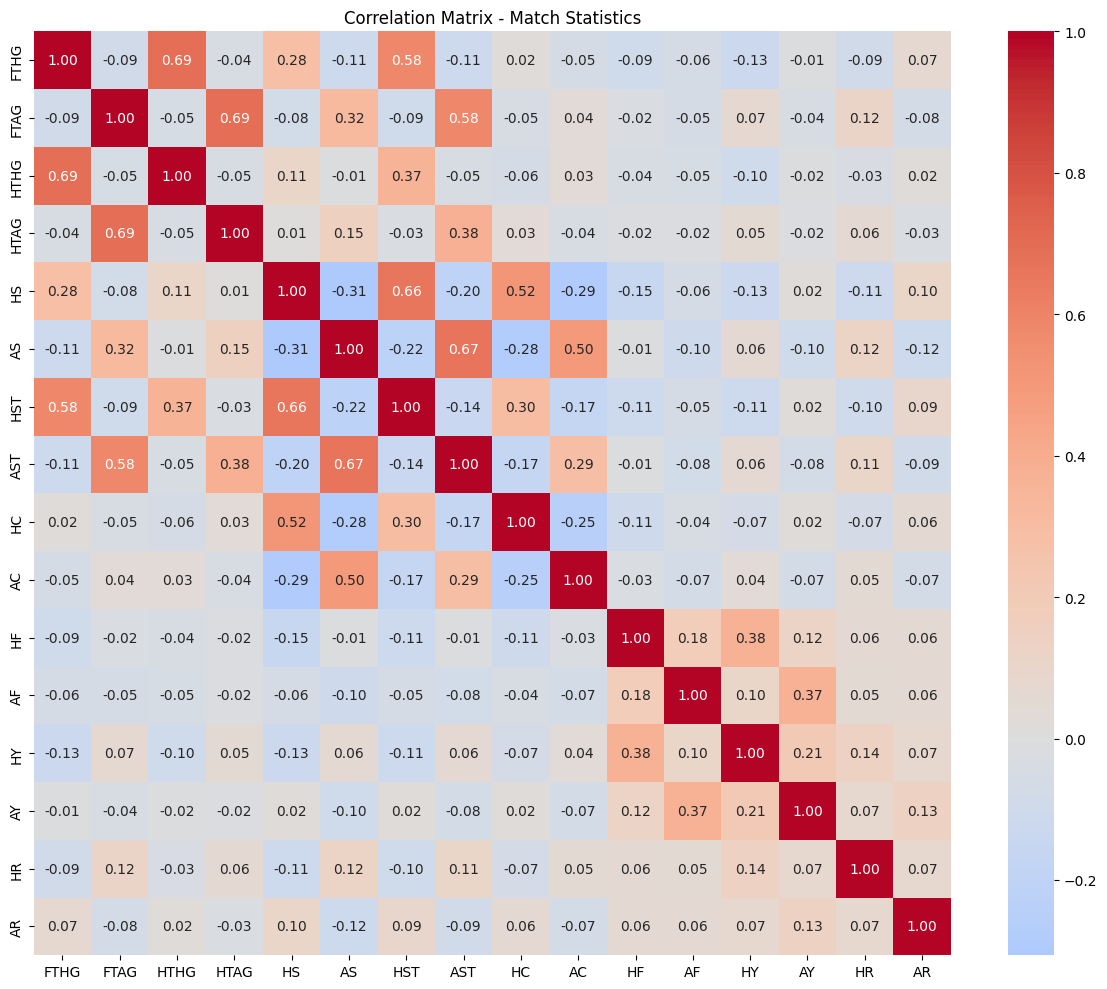

In [80]:
# ----------------------------------------
# Correlation matrix of match statistics
# ----------------------------------------

# Select numerical columns for correlation
num_cols = ['FTHG', 'FTAG', 'HTHG', 'HTAG', 
            'HS', 'AS', 'HST', 'AST',
            'HC', 'AC', 'HF', 'AF',
            'HY', 'AY', 'HR', 'AR']

corr_matrix = df_all[num_cols].corr()

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr_matrix, 
            annot=True, 
            fmt='.2f', 
            cmap='coolwarm',
            center=0,
            ax=ax)

ax.set_title('Correlation Matrix - Match Statistics')
plt.tight_layout()
plt.savefig('../results/figures/03_correlation_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# -----------------------------
# Saving cleaned football data
# -----------------------------

df_all.to_csv('../data/processed/football_cleaned.csv', index=False)
print(f"Saved {df_all.shape[0]} rows to data/processed/football_cleaned.csv")

Saved 19833 rows to data/processed/football_cleaned.csv
